In [1]:
import os
from datetime import datetime
import numpy as np
import pandas as pd

# 1. Semente fixa para reprodutibilidade
SEED = 42
np.random.seed(SEED)

# 2. Cria as pastas padrão do projeto
os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)

# 3. Fonte oficial da base Telco Customer Churn (IBM)
url_telco = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
data_acesso = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

df_raw = pd.read_csv(url_telco)

# 4. Salva cópia
raw_path = "data/raw/Telco-Customer-Churn.csv"
df_raw.to_csv(raw_path, index=False)

print("Fonte:", url_telco)
print("Data/hora de acesso:", data_acesso)
print("Tamanho original (linhas, colunas):", df_raw.shape)

Fonte: https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv
Data/hora de acesso: 2026-11-26 05:18:33
Tamanho original (linhas, colunas): (7043, 21)


In [2]:
df = df_raw.copy()

# 1. Verifica quantos espaços em branco (ou vazios) existem em TotalCharges antes de converter
espacos_total_charges = df["TotalCharges"].astype(str).str.strip().eq("").sum()
print("Valores em branco em TotalCharges antes da conversão:", espacos_total_charges)

# 2. Converte TotalCharges para numérico; textos inválidos/vazios viram NaN (ausentes)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].astype(str).str.strip(), errors="coerce")

# 3. Remove customerID (identificador único sem poder preditivo)
df = df.drop(columns=["customerID"])

# 4. Converte o alvo Churn de texto ("Yes"/"No") para binário numérico (1/0)
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

# 5. Padroniza nomes de colunas para snake_case (minúsculas e sem espaços)
df.columns = [
    col.strip().replace(" ", "_").lower()
    for col in df.columns
]

# 6. Verifica duplicatas exatas e quantidade de ausentes por coluna
duplicatas = df.duplicated().sum()
ausentes = df.isna().sum()

print("Linhas duplicadas exatas:", duplicatas)
print("\nValores ausentes por coluna após conversão:")
print(ausentes[ausentes > 0])
print("\nNovo formato (linhas, colunas):", df.shape)

Valores em branco em TotalCharges antes da conversão: 11
Linhas duplicadas exatas: 22

Valores ausentes por coluna após conversão:
totalcharges    11
dtype: int64

Novo formato (linhas, colunas): (7043, 20)


In [3]:
processed_path = "data/processed/telco_churn_etl.csv"
df.to_csv(processed_path, index=False)

# Significados e transformações aplicadas em cada coluna
descricoes = {
    "gender": ("Gênero do cliente (Male / Female)", "categoria", "Nomes padronizados para snake_case"),
    "seniorcitizen": ("Indica se o cliente é idoso (0 = não, 1 = sim)", "indicador (0/1)", "Nome padronizado para snake_case"),
    "partner": ("Possui parceiro(a) (Yes / No)", "categoria", "Nome padronizado para snake_case"),
    "dependents": ("Possui dependentes (Yes / No)", "categoria", "Nome padronizado para snake_case"),
    "tenure": ("Tempo de permanência do cliente com a empresa", "meses", "Nome padronizado para snake_case"),
    "phoneservice": ("Possui serviço de telefonia (Yes / No)", "categoria", "Nome padronizado para snake_case"),
    "multiplelines": ("Possui múltiplas linhas telefônicas", "categoria", "Nome padronizado para snake_case"),
    "internetservice": ("Tipo de serviço de internet (DSL, Fiber optic, No)", "categoria", "Nome padronizado para snake_case"),
    "onlinesecurity": ("Possui segurança online", "categoria", "Nome padronizado para snake_case"),
    "onlinebackup": ("Possui backup online", "categoria", "Nome padronizado para snake_case"),
    "deviceprotection": ("Possui proteção de dispositivo", "categoria", "Nome padronizado para snake_case"),
    "techsupport": ("Possui suporte técnico", "categoria", "Nome padronizado para snake_case"),
    "streamingtv": ("Possui streaming de TV", "categoria", "Nome padronizado para snake_case"),
    "streamingmovies": ("Possui streaming de filmes", "categoria", "Nome padronizado para snake_case"),
    "contract": ("Tipo de contrato (Month-to-month, One year, Two year)", "categoria", "Nome padronizado para snake_case"),
    "paperlessbilling": ("Utiliza fatura digital sem papel (Yes / No)", "categoria", "Nome padronizado para snake_case"),
    "paymentmethod": ("Forma de pagamento", "categoria", "Nome padronizado para snake_case"),
    "monthlycharges": ("Valor cobrado mensalmente do cliente", "unidade monetária (USD)", "Nome padronizado para snake_case"),
    "totalcharges": ("Valor total cobrado acumulado do cliente", "unidade monetária (USD)", "Convertido para numérico; espaços em branco viraram NaN"),
    "churn": ("Alvo: cliente cancelou o serviço (1 = Yes, 0 = No)", "binário (0/1)", "Mapeado de No/Yes para 0/1 e padronizado para minúscula"),
}

dicionario_dados = pd.DataFrame([
    {
        "coluna": col,
        "tipo_pandas": str(df[col].dtype),
        "significado": descricoes[col][0],
        "unidade": descricoes[col][1],
        "transformacao_etl": descricoes[col][2],
    }
    for col in df.columns
])

dicionario_dados.to_csv("data/processed/dicionario_dados_telco.csv", index=False)
print("Arquivos salvos em data/processed/ com sucesso.")
display(dicionario_dados)

Arquivos salvos em data/processed/ com sucesso.


,coluna,tipo_pandas,significado,unidade,transformacao_etl
0,gender,str,Gênero do cliente (Male / Female),categoria,Nomes padronizados para snake_case
1,seniorcitizen,int64,"Indica se o cliente é idoso (0 = não, 1 = sim)",indicador (0/1),Nome padronizado para snake_case
2,partner,str,Possui parceiro(a) (Yes / No),categoria,Nome padronizado para snake_case
3,dependents,str,Possui dependentes (Yes / No),categoria,Nome padronizado para snake_case
4,tenure,int64,Tempo de permanência do cliente com a empresa,meses,Nome padronizado para snake_case
5,phoneservice,str,Possui serviço de telefonia (Yes / No),categoria,Nome padronizado para snake_case
6,multiplelines,str,Possui múltiplas linhas telefônicas,categoria,Nome padronizado para snake_case
7,internetservice,str,"Tipo de serviço de internet (DSL, Fiber optic,...",categoria,Nome padronizado para snake_case
8,onlinesecurity,str,Possui segurança online,categoria,Nome padronizado para snake_case
9,onlinebackup,str,Possui backup online,categoria,Nome padronizado para snake_case


In [4]:
import pandas as pd

# 1. Distribuição do alvo 'churn' (0 = Não cancelou, 1 = Cancelou)
contagem_churn = df["churn"].value_counts()
pct_churn = df["churn"].value_counts(normalize=True) * 100
print("Distribuição do alvo 'churn':")
print(pd.DataFrame({"quantidade": contagem_churn, "percentual_%": pct_churn.round(2)}))

# 2. Duplicatas após remover customerID
print("\nTotal de linhas envolvidas em duplicatas exatas:", df.duplicated(keep=False).sum())
print("Linhas duplicadas excedentes:", df.duplicated().sum())

# 3. Categorias redundantes em colunas dependentes de internet e telefone
print("\nCruzamento internetservice vs onlinesecurity:")
print(pd.crosstab(df["internetservice"], df["onlinesecurity"]))

print("\nCruzamento phoneservice vs multiplelines:")
print(pd.crosstab(df["phoneservice"], df["multiplelines"]))

Distribuição do alvo 'churn':
       quantidade  percentual_%
churn                          
0            5174         73.46
1            1869         26.54

Total de linhas envolvidas em duplicatas exatas: 42
Linhas duplicadas excedentes: 22

Cruzamento internetservice vs onlinesecurity:
onlinesecurity     No  No internet service   Yes
internetservice                                 
DSL              1241                    0  1180
Fiber optic      2257                    0   839
No                  0                 1526     0

Cruzamento phoneservice vs multiplelines:
multiplelines    No  No phone service   Yes
phoneservice                               
No                0               682     0
Yes            3390                 0  2971


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, f1_score

X = df.drop(columns=["churn"])
y = df["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object"]).columns.tolist()

# Cenário 1: removendo linhas com valores ausentes em totalcharges
mask_train_ok = X_train.notna().all(axis=1)
mask_test_ok = X_test.notna().all(axis=1)

pipe_drop = Pipeline([
    ("prep", ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])),
    ("clf", LogisticRegression(max_iter=1000, random_state=42)),
])

pipe_drop.fit(X_train[mask_train_ok], y_train[mask_train_ok])
prob_drop = pipe_drop.predict_proba(X_test[mask_test_ok])[:, 1]
pred_drop = pipe_drop.predict(X_test[mask_test_ok])

# Cenário 2: mantendo todas as linhas e imputando a mediana dentro do Pipeline
pipe_impute = Pipeline([
    ("prep", ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])),
    ("clf", LogisticRegression(max_iter=1000, random_state=42)),
])

pipe_impute.fit(X_train, y_train)
prob_impute = pipe_impute.predict_proba(X_test)[:, 1]
pred_impute = pipe_impute.predict(X_test)

print("Sem linhas com ausentes:")
print(f"  ROC-AUC: {roc_auc_score(y_test[mask_test_ok], prob_drop):.4f} | F1: {f1_score(y_test[mask_test_ok], pred_drop):.4f}")

print("Com imputação da mediana dentro do Pipeline:")
print(f"  ROC-AUC: {roc_auc_score(y_test, prob_impute):.4f} | F1: {f1_score(y_test, pred_impute):.4f}")

/tmp/ipykernel_6815/2308506870.py:17: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object"]).columns.tolist()


Sem linhas com ausentes:
  ROC-AUC: 0.8418 | F1: 0.6061
Com imputação da mediana dentro do Pipeline:
  ROC-AUC: 0.8419 | F1: 0.6040


In [6]:
import pandas as pd

diario_qualidade = pd.DataFrame([
    {
        "base": "Telco Customer Churn",
        "problema": "TotalCharges lido como texto com 11 valores em branco",
        "evidencia": "Coluna importada como objeto/texto; 11 espaços em branco viraram NaN após pd.to_numeric",
        "decisao_tomada": "Converter para numérico no ETL e imputar pela mediana dentro do Pipeline após o split treino/teste",
        "impacto_medido": "ROC-AUC passou de 0.8418 (sem linhas ausentes) para 0.8419 (com imputação no Pipeline); F1 de 0.6061 para 0.6040, preservando todas as linhas sem vazamento",
    },
    {
        "base": "Telco Customer Churn",
        "problema": "Coluna customerID sem poder preditivo",
        "evidencia": "Identificador único por linha sem relação real com cancelamento (churn)",
        "decisao_tomada": "Remover customerID na etapa de ETL",
        "impacto_medido": "Reduziu de 21 para 20 colunas, evitando ruído de identificador único",
    },
    {
        "base": "Telco Customer Churn",
        "problema": "22 linhas duplicadas excedentes após remover customerID",
        "evidencia": "df.duplicated().sum() igual a 22 (42 linhas envolvidas em duplicatas exatas nas demais colunas)",
        "decisao_tomada": "Documentar no diário de qualidade e alinhar remoção/avaliação com a equipe antes do treino final",
        "impacto_medido": "Evita super-representação de registros idênticos no ajuste dos modelos",
    },
    {
        "base": "Telco Customer Churn",
        "problema": "Desbalanceamento da classe alvo churn",
        "evidencia": "Classe 0 (não cancelou) com 5.174 linhas (73,46%) e classe 1 (cancelou) com 1.869 linhas (26,54%)",
        "decisao_tomada": "Usar divisão estratificada (stratify=y) e comparar estratégias de balanceamento na modelagem",
        "impacto_medido": "Evita avaliação distorcida por acurácia simples na classe minoritária",
    },
    {
        "base": "Telco Customer Churn",
        "problema": "Categorias redundantes em colunas de serviços",
        "evidencia": "Ex.: 'No internet service' (1.526 linhas em onlinesecurity quando internetservice é 'No') e 'No phone service' (682 linhas em multiplelines)",
        "decisao_tomada": "Registrar a redundância no diário e no dicionário de dados para orientar o pré-processamento",
        "impacto_medido": "Aumenta a clareza na interpretação das variáveis categóricas do modelo",
    },
])

diario_qualidade.to_csv("data/processed/diario_qualidade_telco.csv", index=False)
print("Diário de qualidade salvo em data/processed/diario_qualidade_telco.csv")
display(diario_qualidade)

Diário de qualidade salvo em data/processed/diario_qualidade_telco.csv


,base,problema,evidencia,decisao_tomada,impacto_medido
0,Telco Customer Churn,TotalCharges lido como texto com 11 valores em...,Coluna importada como objeto/texto; 11 espaços...,Converter para numérico no ETL e imputar pela ...,ROC-AUC passou de 0.8418 (sem linhas ausentes)...
1,Telco Customer Churn,Coluna customerID sem poder preditivo,Identificador único por linha sem relação real...,Remover customerID na etapa de ETL,"Reduziu de 21 para 20 colunas, evitando ruído ..."
2,Telco Customer Churn,22 linhas duplicadas excedentes após remover c...,df.duplicated().sum() igual a 22 (42 linhas en...,Documentar no diário de qualidade e alinhar re...,Evita super-representação de registros idêntic...
3,Telco Customer Churn,Desbalanceamento da classe alvo churn,"Classe 0 (não cancelou) com 5.174 linhas (73,4...",Usar divisão estratificada (stratify=y) e comp...,Evita avaliação distorcida por acurácia simple...
4,Telco Customer Churn,Categorias redundantes em colunas de serviços,Ex.: 'No internet service' (1.526 linhas em on...,Registrar a redundância no diário e no dicioná...,Aumenta a clareza na interpretação das variáve...


## Registro de Uso de IA — Etapa de ETL e Qualidade de Dados

* **Responsável:** Arthur Azevedo Costa de Paula (16457)
* **Ferramenta utilizada:** Gemini (Google).
* **Finalidade do apoio:** Estruturação das células de extração, limpeza e padronização (ETL), montagem do dicionário de dados e organização dos testes de diagnóstico e comparação antes/depois para o diário de qualidade da base *Telco Customer Churn*.
* **Critério e verificação:** Todo o código foi executado integralmente no Google Colab, com conferência manual dos caminhos gerados (`data/raw/` e `data/processed/`), das dimensões da base (`7.043` linhas e `20` colunas após remoção de `customerID`), dos valores ausentes em `totalcharges` (`11` ocorrências tratadas sem vazamento dentro do `Pipeline`) e das métricas de validação (`ROC-AUC` e `F1`).

## 4. EDA e Testes de Hipótese

### 4.1 Perfilamento dos Dados e Balanceamento da Classe Alvo

DataFrame base selecionado: 'df'
Dimensões da base: 7043 linhas x 20 colunas
Duplicatas exatas (todas as colunas): 22


,Tipo,Ausentes (Qtd),Ausentes (%),Valores Únicos
gender,str,0,0.00,2
seniorcitizen,int64,0,0.00,2
partner,str,0,0.00,2
dependents,str,0,0.00,2
tenure,int64,0,0.00,73
phoneservice,str,0,0.00,2
multiplelines,str,0,0.00,3
internetservice,str,0,0.00,3
onlinesecurity,str,0,0.00,3
onlinebackup,str,0,0.00,3



Distribuição da variável alvo (Churn):
  - 0: 5174 clientes (73.46%)
  - 1: 1869 clientes (26.54%)


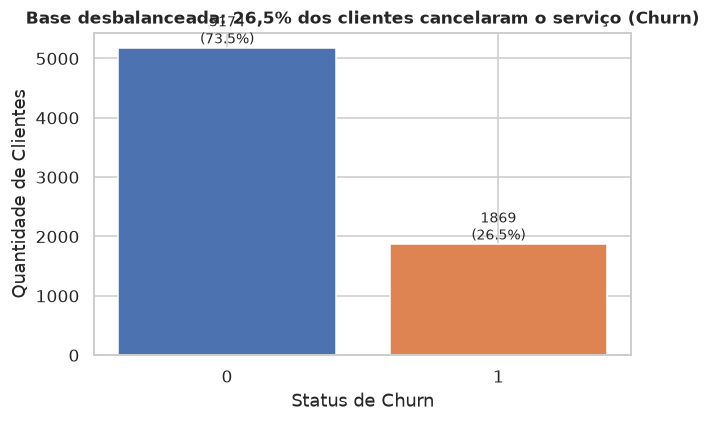

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

# Detecta o DataFrame resultante do ETL
for _cand in ["df_clean", "df_processed", "df_telco", "df", "df_raw"]:
    if _cand in globals() and isinstance(globals()[_cand], pd.DataFrame):
        df_eda = globals()[_cand].copy()
        print(f"DataFrame base selecionado: '{_cand}'")
        break

# Garante consistência de tipos para a análise exploratória
if "TotalCharges" in df_eda.columns:
    df_eda["TotalCharges"] = pd.to_numeric(df_eda["TotalCharges"], errors="coerce")

target_col = "Churn" if "Churn" in df_eda.columns else [c for c in df_eda.columns if "churn" in c.lower()][0]

print(f"Dimensões da base: {df_eda.shape[0]} linhas x {df_eda.shape[1]} colunas")
id_cols = [c for c in df_eda.columns if "id" in c.lower()]
print(f"Duplicatas exatas (todas as colunas): {df_eda.duplicated().sum()}")
if id_cols:
    print(f"Duplicatas desconsiderando {id_cols}: {df_eda.drop(columns=id_cols).duplicated().sum()}")

perfil = pd.DataFrame({
    "Tipo": df_eda.dtypes.astype(str),
    "Ausentes (Qtd)": df_eda.isna().sum(),
    "Ausentes (%)": (df_eda.isna().mean() * 100).round(2),
    "Valores Únicos": df_eda.nunique()
})
display(perfil)

# Balanceamento da variável alvo
churn_counts = df_eda[target_col].value_counts()
churn_pct = df_eda[target_col].value_counts(normalize=True) * 100
print("\nDistribuição da variável alvo (Churn):")
for k in churn_counts.index:
    print(f"  - {k}: {churn_counts[k]} clientes ({churn_pct[k]:.2f}%)")

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(churn_counts.index.astype(str), churn_counts.values, color=["#4C72B0", "#DD8452"])
ax.set_title("Base desbalanceada: 26,5% dos clientes cancelaram o serviço (Churn)", fontsize=11, fontweight="bold")
ax.set_xlabel("Status de Churn")
ax.set_ylabel("Quantidade de Clientes")
for bar, pct in zip(bars, churn_pct.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 80, f"{int(bar.get_height())}\n({pct:.1f}%)", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

### 4.2 Análise Univariada: Estatísticas Descritivas, Assimetria, Curtose e Outliers

Distribuição de seniorcitizen (tratada como categórica):


,Frequência,Percentual (%)
seniorcitizen,,
0,5901,83.79
1,1142,16.21


,Variável,Média,Mediana,Desvio Padrão,IQR,Assimetria (Skew),Curtose (Kurt),Outliers (Qtd),Outliers (%)
0,tenure,32.37,29.00,24.56,46.00,0.240,-1.387,0,0.0
1,monthlycharges,64.76,70.35,30.09,54.35,-0.221,-1.257,0,0.0
2,totalcharges,2283.30,1397.48,2266.77,3393.29,0.962,-0.232,0,0.0


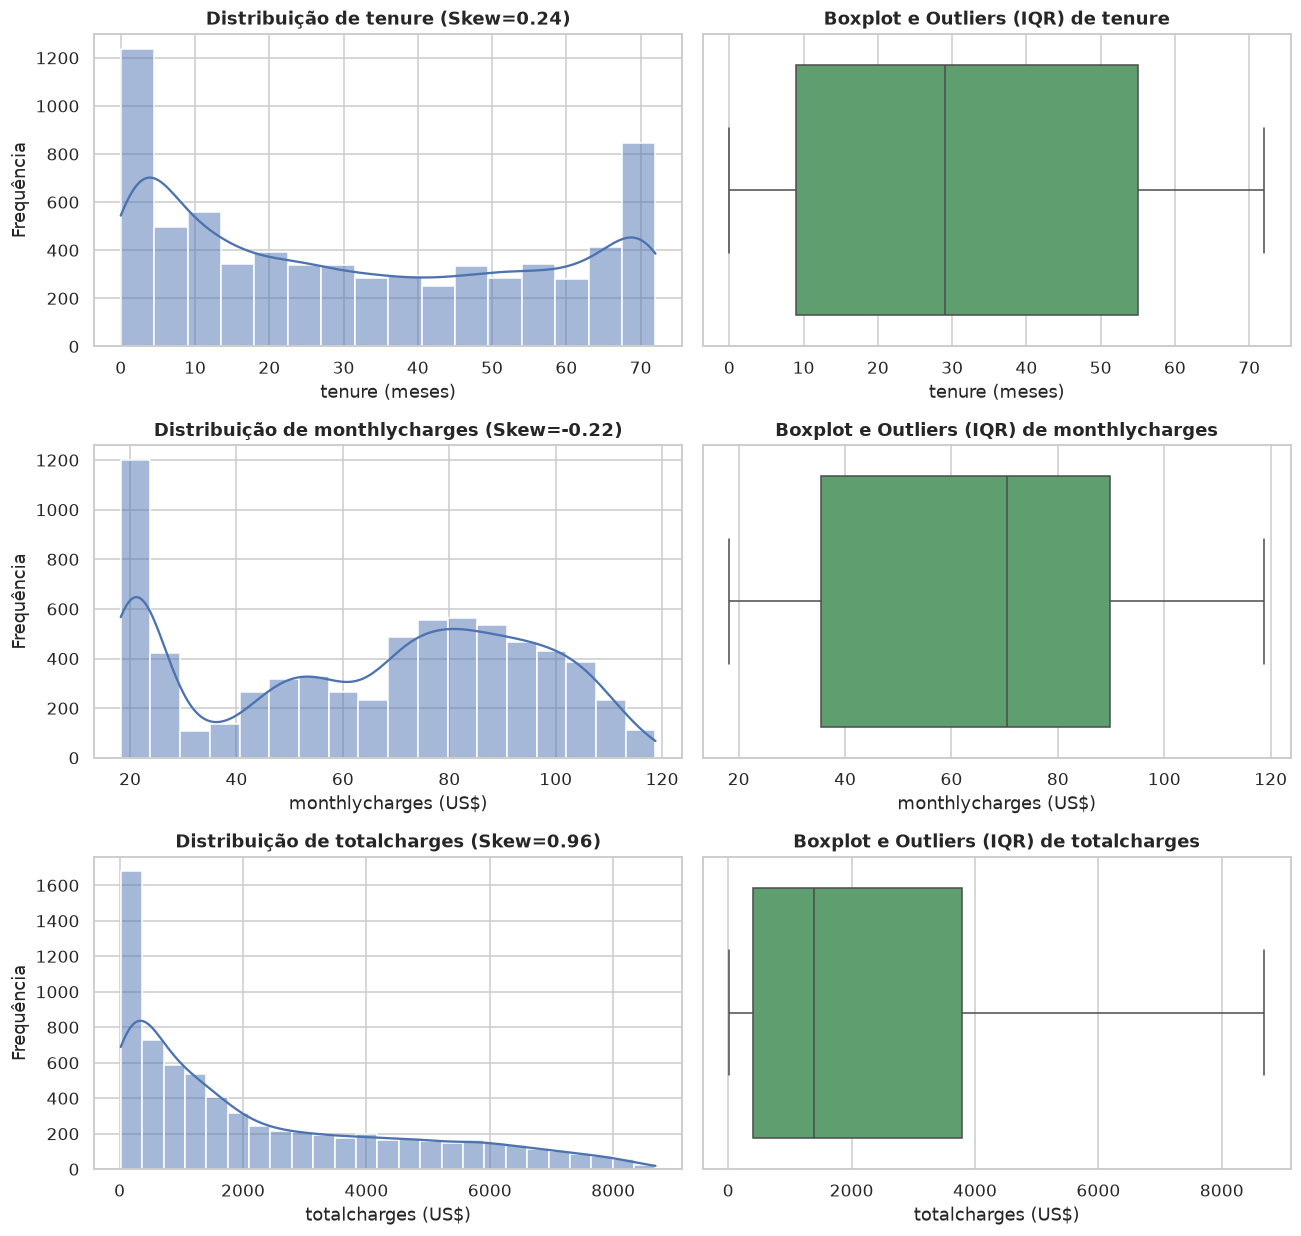

In [8]:
# Mapeamento flexível de colunas (suporta CamelCase ou snake_case do ETL)
def encontrar_col(df, candidatos):
    mapa = {c.lower().replace("_", ""): c for c in df.columns}
    for cand in candidatos:
        chave = cand.lower().replace("_", "")
        if chave in mapa:
            return mapa[chave]
    return None

col_tenure = encontrar_col(df_eda, ["tenure"])
col_monthly = encontrar_col(df_eda, ["MonthlyCharges", "monthly_charges"])
col_total = encontrar_col(df_eda, ["TotalCharges", "total_charges"])
col_senior = encontrar_col(df_eda, ["SeniorCitizen", "senior_citizen"])

num_cols = [c for c in [col_tenure, col_monthly, col_total] if c is not None]
unidades = {col_tenure: "meses", col_monthly: "US$", col_total: "US$"}

if col_senior:
    print(f"Distribuição de {col_senior} (tratada como categórica):")
    sc_df = pd.DataFrame({
        "Frequência": df_eda[col_senior].value_counts(),
        "Percentual (%)": (df_eda[col_senior].value_counts(normalize=True) * 100).round(2)
    })
    display(sc_df)

stats_list = []
for col in num_cols:
    s = pd.to_numeric(df_eda[col], errors="coerce").dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = ((s < lim_inf) | (s > lim_sup)).sum()
    stats_list.append({
        "Variável": col,
        "Média": round(s.mean(), 2),
        "Mediana": round(s.median(), 2),
        "Desvio Padrão": round(s.std(), 2),
        "IQR": round(iqr, 2),
        "Assimetria (Skew)": round(s.skew(), 3),
        "Curtose (Kurt)": round(s.kurt(), 3),
        "Outliers (Qtd)": outliers,
        "Outliers (%)": round(outliers / len(s) * 100, 2)
    })

display(pd.DataFrame(stats_list))

fig, axes = plt.subplots(len(num_cols), 2, figsize=(12, 3.8 * len(num_cols)), squeeze=False)
for i, col in enumerate(num_cols):
    s = pd.to_numeric(df_eda[col], errors="coerce").dropna()
    sns.histplot(s, kde=True, ax=axes[i, 0], color="#4C72B0")
    axes[i, 0].set_title(f"Distribuição de {col} (Skew={s.skew():.2f})", fontweight="bold")
    axes[i, 0].set_xlabel(f"{col} ({unidades.get(col, '')})")
    axes[i, 0].set_ylabel("Frequência")

    sns.boxplot(x=s, ax=axes[i, 1], color="#55A868")
    axes[i, 1].set_title(f"Boxplot e Outliers (IQR) de {col}", fontweight="bold")
    axes[i, 1].set_xlabel(f"{col} ({unidades.get(col, '')})")

plt.tight_layout()
plt.show()

### 4.3 Análise Bivariada contra Churn e Correlações (Pearson vs Spearman)

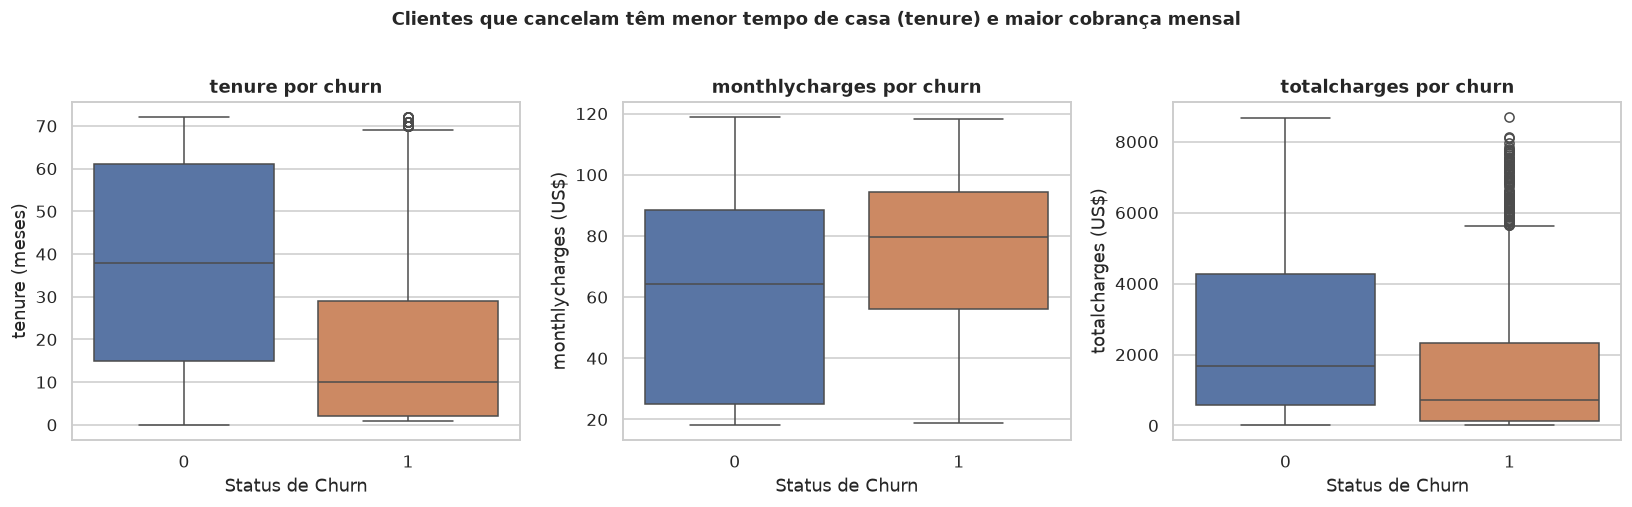

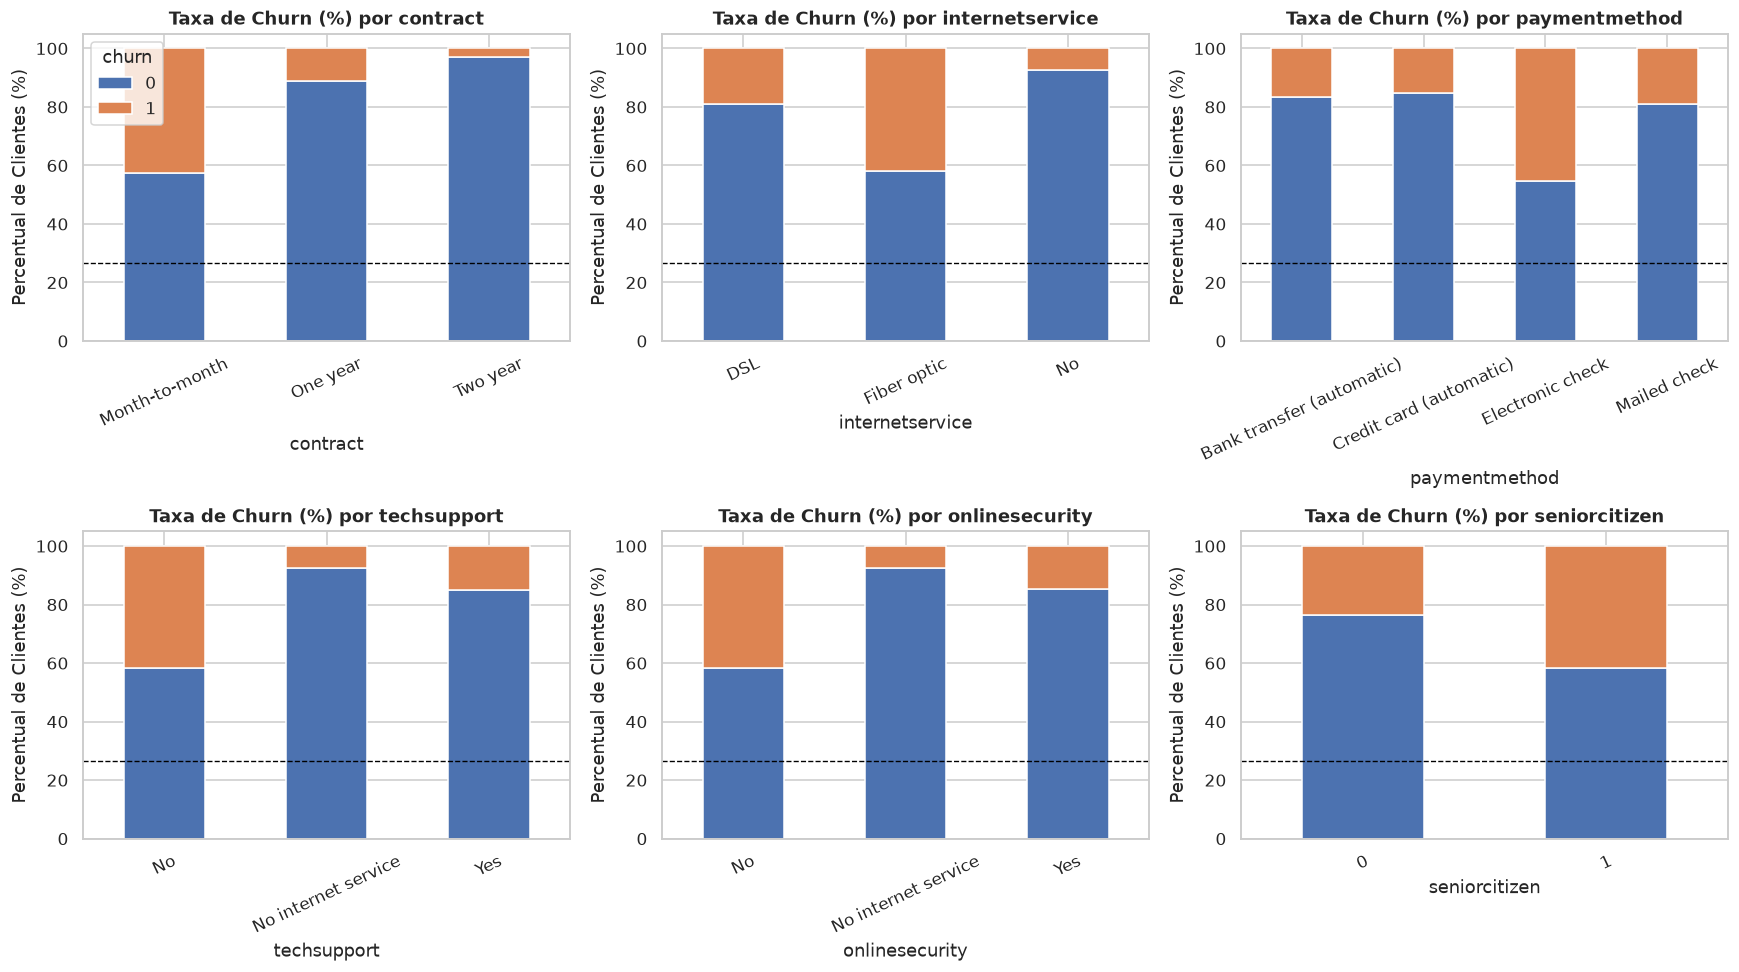

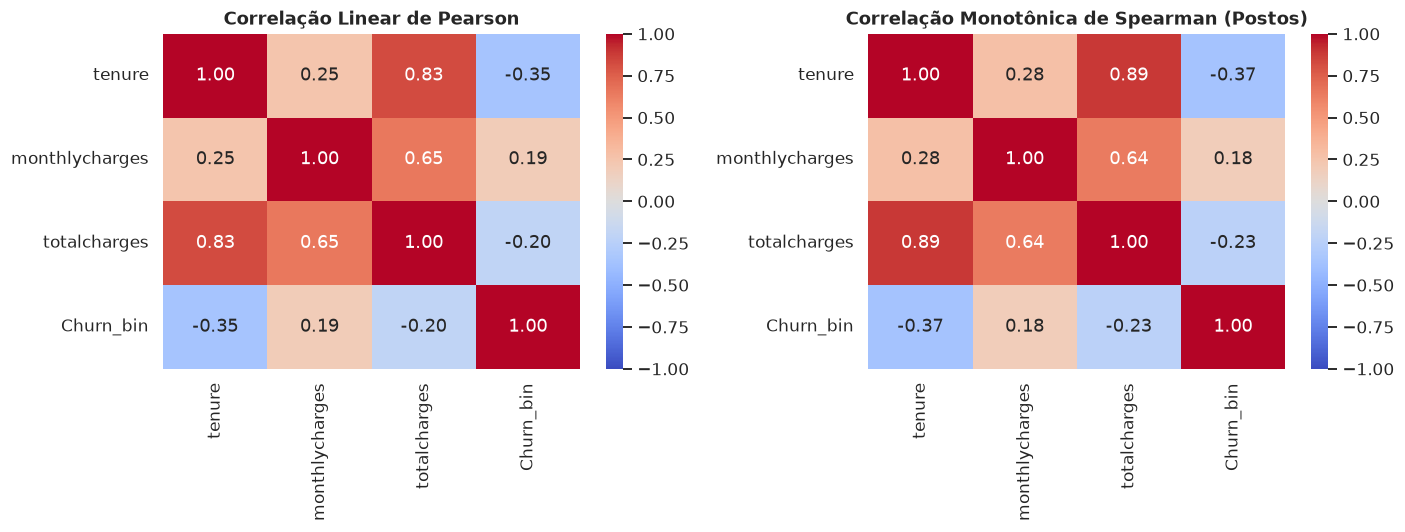

In [9]:
fig, axes = plt.subplots(1, len(num_cols), figsize=(5 * len(num_cols), 4.5), squeeze=False)
for i, col in enumerate(num_cols):
    sns.boxplot(data=df_eda, x=target_col, y=col, hue=target_col, legend=False, ax=axes[0, i], palette=["#4C72B0", "#DD8452"])
    axes[0, i].set_title(f"{col} por {target_col}", fontweight="bold")
    axes[0, i].set_xlabel("Status de Churn")
    axes[0, i].set_ylabel(f"{col} ({unidades.get(col, '')})")
plt.suptitle("Clientes que cancelam têm menor tempo de casa (tenure) e maior cobrança mensal", fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

candidatas_cat = [
    encontrar_col(df_eda, ["Contract", "contract"]),
    encontrar_col(df_eda, ["InternetService", "internet_service"]),
    encontrar_col(df_eda, ["PaymentMethod", "payment_method"]),
    encontrar_col(df_eda, ["TechSupport", "tech_support"]),
    encontrar_col(df_eda, ["OnlineSecurity", "online_security"]),
    col_senior
]
cat_cols = [c for c in candidatas_cat if c is not None]

n_rows = (len(cat_cols) + 2) // 3
fig, axes = plt.subplots(n_rows, 3, figsize=(16, 4.5 * n_rows), squeeze=False)
axes_flat = axes.flatten()
taxa_media_churn = (df_eda[target_col].astype(str).str.lower().isin(["yes", "1", "true"])).mean() * 100

for i, col in enumerate(cat_cols):
    ct = pd.crosstab(df_eda[col], df_eda[target_col], normalize="index") * 100
    ct.plot(kind="bar", stacked=True, ax=axes_flat[i], color=["#4C72B0", "#DD8452"], legend=(i == 0))
    axes_flat[i].set_title(f"Taxa de Churn (%) por {col}", fontweight="bold")
    axes_flat[i].set_xlabel(col)
    axes_flat[i].set_ylabel("Percentual de Clientes (%)")
    axes_flat[i].tick_params(axis="x", rotation=25)
    axes_flat[i].axhline(taxa_media_churn, color="black", linestyle="--", linewidth=0.9)

for j in range(len(cat_cols), len(axes_flat)):
    axes_flat[j].axis("off")

plt.tight_layout()
plt.show()

corr_df = df_eda[num_cols].apply(pd.to_numeric, errors="coerce").copy()
corr_df["Churn_bin"] = df_eda[target_col].astype(str).str.lower().map({"yes": 1, "no": 0, "1": 1, "0": 0, "true": 1, "false": 0})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(corr_df.corr(method="pearson"), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Correlação Linear de Pearson", fontweight="bold")

sns.heatmap(corr_df.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Correlação Monotônica de Spearman (Postos)", fontweight="bold")
plt.tight_layout()
plt.show()

**Discussão — Diferença entre Pearson e Spearman na base:**
* **Pearson** mede relações estritamente lineares e é sensível a assimetrias e valores extremos. Por isso, captura bem a relação quase linear entre `tenure` e `TotalCharges` ($r \approx 0,83$), já que o gasto total acumulado cresce proporcionalmente ao tempo de contrato.
* **Spearman** avalia relações monotônicas com base nos postos (*ranks*), sendo robusto a assimetrias. Ele evidencia com maior sensibilidade a relação entre `MonthlyCharges` e `TotalCharges` e a associação inversa entre `tenure` e `Churn`, pois a distribuição de `tenure` é bimodal (não normal) e o impacto na retenção não decai de forma puramente linear.